# Лабораторная работа № 2
## Классификация. Нейронные сети

**Датасет** — MAGIC Gamma Telescope. **Задача** — по форме и яркости вспышки определить, вызвана ли она гамма-квантом или адронным фоном.

### 1. Введение

Цель работы — сравнить пять методов классификации из Scikit-Learn и полносвязную нейронную сеть на TensorFlow. Для каждой модели подберём гиперпараметры, построим ROC-кривую и оценим Accuracy, Precision, Recall, F1 и ROC-AUC. Для нейросети отдельно проследим по журналам TensorBoard, как меняются потери и точность на обучении и валидации.

In [1]:
import json
import os
from datetime import datetime, timezone
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path(".cache/matplotlib").resolve()))
os.environ.setdefault("XDG_CACHE_HOME", str(Path(".cache").resolve()))
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("KERAS_BACKEND", "tensorflow")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import BernoulliNB, ComplementNB, GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

SEED = 42
RESULTS = Path("results")
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "savefig.dpi": 140, "figure.facecolor": "white",
})

def show_figure(fig, filename):
    fig.savefig(FIGURES / filename, bbox_inches="tight")
    plt.show()

print(f"NumPy {np.__version__}, Pandas {pd.__version__}, Scikit-Learn {sklearn.__version__}, seed = {SEED}")

NumPy 2.2.6, Pandas 2.2.3, Scikit-Learn 1.8.0, seed = 42


### 2. Выбор и подготовка датасета

Первичный гамма-квант или адрон порождает в атмосфере каскад частиц. Телескоп регистрирует короткую вспышку черенковского света. В MAGIC Gamma Telescope такие события **смоделированы методом Монте-Карло**. Каждая строка описывает одно изображение вспышки десятью непрерывными признаками. Положительный класс `g` — гамма-сигнал, класс `h` — адронный фон. [Kaggle](https://www.kaggle.com/datasets/abhinand05/magic-gamma-telescope-dataset) · [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/159/magic+gamma+telescope)

| Признаки | Что измеряют |
|---|---|
| `fLength`, `fWidth` | Большая и малая оси эллипса вспышки, мм |
| `fSize` | Десятичный логарифм суммарного сигнала пикселей |
| `fConc`, `fConc1` | Доля суммарного сигнала в двух самых ярких пикселях и в одном самом ярком пикселе |
| `fAsym` | Смещение самого яркого пикселя относительно центра вдоль большой оси, мм |
| `fM3Long`, `fM3Trans` | Кубические корни третьих центральных моментов вдоль большой и малой осей, мм |
| `fAlpha` | Угол между большой осью и направлением к началу координат, градусы |
| `fDist` | Расстояние от начала координат до центра вспышки, мм |

Файл `data/magic04.data` хранится в формате CSV без заголовка. Столбцы заданы явно. В некоторых копиях есть порядковый номер `Event`. Поскольку исходные записи упорядочены по классу, такой номер раскрывает ответ. В признаки входят только десять физических характеристик.

In [2]:
FEATURES = [
    "fLength", "fWidth", "fSize", "fConc", "fConc1",
    "fAsym", "fM3Long", "fM3Trans", "fAlpha", "fDist",
]
raw = pd.read_csv("data/magic04.data", header=None, names=[*FEATURES, "class"])
display(raw.head())
print(f"Строк: {len(raw)}, признаков: {len(FEATURES)}")
print(f"Пропущенных значений: {raw.isna().sum().sum()}")
print(f"Полных дубликатов: {raw.duplicated().sum()}")

assert set(raw["class"]) == {"g", "h"} and raw["class"].notna().all()
assert np.isfinite(raw[FEATURES].to_numpy()).all()
clean = raw.drop_duplicates()
# После удаления повторов у каждого вектора признаков единственная метка.
assert not clean.duplicated(subset=FEATURES).any()

class_counts = pd.concat(
    [raw["class"].value_counts(), clean["class"].value_counts()], axis=1
)
class_counts.columns = ["До очистки", "После очистки"]
display(class_counts.rename(index={"g": "Гамма", "h": "Фон"}))
print(f"После очистки: {len(clean)} событий")

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


Строк: 19020, признаков: 10
Пропущенных значений: 0
Полных дубликатов: 115


,До очистки,После очистки
class,,
Гамма,12332,12332
Фон,6688,6573


После очистки: 18905 событий


Все значения конечны. Удалены 115 точных повторов фоновых событий до разбиения, чтобы копии одной строки не попадали в разные выборки. В результате осталось 12 332 гамма-события и 6 573 фоновых. Для этой таблицы заполнение пропусков не потребовалось. Отрицательные значения проекций и моментов имеют физический смысл и сохранены.

### 3. Разбиение выборки

Сначала выделим 20% для валидации со стратификацией и seed 42. Именно эта часть служила для предварительной проверки пригодности датасета. Из оставшихся событий независимо выделим четверть для финального теста с seed 43. Доли обучения, валидации и теста составят 60/20/20. На обучении подберём параметры классических моделей по трём фолдам, по валидации сравним сети и выберем метод. Перед тестовой оценкой переобучим каждую модель на объединении обучения и валидации.

In [3]:
X = clean[FEATURES]
y = clean["class"].map({"h": 0, "g": 1})
X_pool, X_val, y_pool, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED,
)
X_train, X_test, y_train, y_test = train_test_split(
    X_pool, y_pool, test_size=0.25, stratify=y_pool, random_state=SEED + 1,
)
X_dev = pd.concat([X_train, X_val])
y_dev = pd.concat([y_train, y_val])

parts = {"Обучение": y_train, "Валидация": y_val, "Тест": y_test}
split_table = pd.DataFrame({
    part: {"Всего": len(labels), "Гамма": int(labels.sum()),
           "Фон": int((labels == 0).sum()), "Доля гамма": labels.mean()}
    for part, labels in parts.items()
}).T
display(split_table.astype({"Всего": int, "Гамма": int, "Фон": int}).round(4))
assert pd.concat(parts.values()).index.is_unique
assert sum(map(len, parts.values())) == len(clean)

,Всего,Гамма,Фон,Доля гамма
Обучение,11343,7400,3943,0.6524
Валидация,3781,2466,1315,0.6522
Тест,3781,2466,1315,0.6522


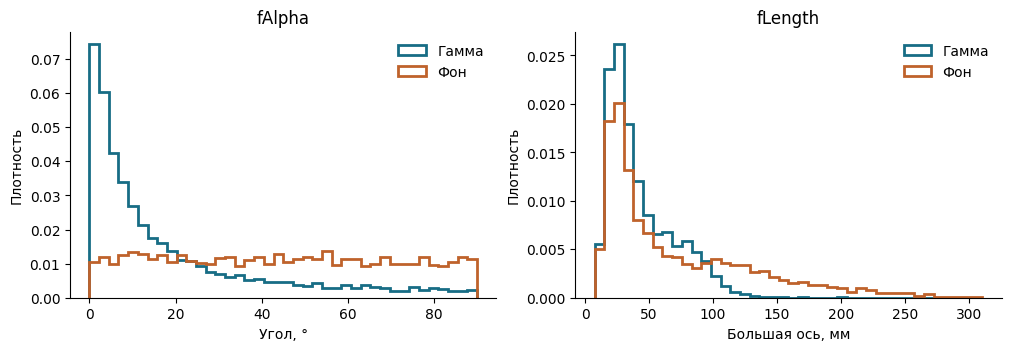

,fAlpha,fLength
class,,
Фон,44.11,46.97
Гамма,9.81,34.46


In [4]:
class_styles = [(1, "Гамма", "#176d85"), (0, "Фон", "#bf622b")]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), constrained_layout=True)
for ax, feature, label in zip(axes, ["fAlpha", "fLength"], ["Угол, °", "Большая ось, мм"]):
    edges = np.histogram_bin_edges(X_train[feature], bins=40)
    for target, title, color in class_styles:
        values = X_train.loc[y_train == target, feature]
        ax.hist(values, bins=edges, density=True, histtype="step", linewidth=2,
                label=title, color=color)
    ax.set(title=feature, xlabel=label, ylabel="Плотность")
    ax.legend(frameon=False)
show_figure(fig, "01_distributions.png")
display(X_train.groupby(y_train)[["fAlpha", "fLength"]].median()
        .rename(index={0: "Фон", 1: "Гамма"}).round(2))

На обучении медиана угла `fAlpha` равна 9,81° у гамма-событий и 44,11° у фона. Большая ось тоже обычно короче у гамма-событий (медианы 34,46 и 46,97 мм). Диапазоны перекрываются, поэтому одного порога по углу или длине недостаточно для разделения классов.

### 4. Методы классификации и метрики

| Модель | Как строится решение | Что подбирается |
|---|---|---|
| GaussianNB | Условное распределение каждого признака внутри класса аппроксимируется нормальным. Байесовское правило объединяет вклады признаков | Добавка к дисперсии `var_smoothing` |
| MultinomialNB | Сравнивает частоты попадания признаков в интервалы для каждого класса | Число интервалов и сглаживание `alpha` |
| ComplementNB | Оценивает веса индикаторов по наблюдениям остальных классов | Число интервалов и `alpha` |
| BernoulliNB | Учитывает и наличие, и отсутствие каждого бинарного индикатора | Число интервалов и `alpha` |
| Дерево решений | Последовательно делит выборку по порогам признаков, уменьшая неоднородность Джини | Глубина дерева и минимальный размер листа |
| LDA | Оценивает средние классов и общую ковариационную матрицу, строит линейную границу | Степень регуляризации ковариационной матрицы `shrinkage` |
| SVM | Строит разделяющую поверхность с зазором. RBF-ядро позволяет ей быть нелинейной | Штраф за ошибки `C` и коэффициент ядра `gamma` |
| k-NN | Голосование ближайших объектов по евклидову расстоянию | Число соседей и веса их голосов |

Наивные байесовские классификаторы предполагают условную независимость признаков внутри каждого класса. Для трёх дискретных вариантов Байеса разобьём каждый признак по квантилям и закодируем номер интервала бинарными индикаторами. Для одного события ровно десять индикаторов равны единице — по одному на признак. Это даёт неотрицательные счётчики для MultinomialNB и ComplementNB и бинарные входы для BernoulliNB. Для GaussianNB, LDA, SVM и k-NN используем стандартизацию. Дерево получает исходные значения. Все обучаемые преобразования входят в `Pipeline` и заново рассчитываются на обучающей части каждого фолда.

Обозначим верно найденный гамма-сигнал как TP, фон, ошибочно принятый за сигнал, как FP, пропущенный сигнал как FN и верно распознанный фон как TN.

| Метрика | Расчёт и смысл |
|---|---|
| Accuracy | (TP + TN) / N — доля верных решений |
| Precision | TP / (TP + FP) — чистота отобранных гамма-событий |
| Recall | TP / (TP + FN) — доля обнаруженного гамма-сигнала |
| F1 | 2 · Precision · Recall / (Precision + Recall) |
| ROC-AUC | Площадь под кривой TPR от FPR при изменении порога. Эквивалентна вероятности ранжировать случайный сигнал выше случайного фона, с учётом ничьих |

Критерий выбора — ROC-AUC. Для SVM используем значение решающей функции `decision_function`, для LDA — её решающую функцию, для остальных моделей — оценку вероятности класса `g`. Четыре пороговые метрики считаем по стандартному решению модели. У нейросети порог равен 0,5.

In [5]:
def scaled(model):
    return Pipeline([("scale", StandardScaler()), ("model", model)])

def binned(model):
    bins = KBinsDiscretizer(
        strategy="quantile", encode="onehot", quantile_method="linear", subsample=None,
    )
    return Pipeline([("bins", bins), ("model", model)])

bin_grid = {"bins__n_bins": [4, 8, 16], "model__alpha": [0.1, 1.0, 10.0]}
experiments = {
    "GaussianNB": (scaled(GaussianNB()),
                   {"model__var_smoothing": [1e-9, 0.01, 0.1, 1.0]}),
    "MultinomialNB": (binned(MultinomialNB()), bin_grid),
    "ComplementNB": (binned(ComplementNB()), bin_grid),
    "BernoulliNB": (binned(BernoulliNB(binarize=None)), bin_grid),
    "Decision Tree": (Pipeline([("model", DecisionTreeClassifier(random_state=SEED))]),
                      {"model__max_depth": [4, 8, 16], "model__min_samples_leaf": [1, 20]}),
    "LDA": (scaled(LinearDiscriminantAnalysis(solver="lsqr")),
            {"model__shrinkage": [0, 0.05, 0.2, 0.6, 1.0]}),
    "SVM (RBF)": (scaled(SVC(kernel="rbf", cache_size=256)),
                  {"model__C": [1.0, 10.0], "model__gamma": [0.03, 0.1, 0.3]}),
    "k-NN": (scaled(KNeighborsClassifier()),
             {"model__n_neighbors": [5, 15, 35], "model__weights": ["uniform", "distance"]}),
}

def signal_score(estimator, features):
    if hasattr(estimator, "decision_function"):
        return estimator.decision_function(features)
    return estimator.predict_proba(features)[:, 1]

### 5. Настройка гиперпараметров

Для классических методов используем `GridSearchCV` с одинаковыми тремя стратифицированными фолдами. Для каждой конфигурации сохраняем ROC-AUC на каждом фолде, среднее и стандартное отклонение. Из каждой сетки выбираем конфигурацию с максимальным средним ROC-AUC, обучаем её на всей обучающей части и оцениваем на валидации.

In [6]:
folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
best_estimators = {}
validation_auc = {}
trials, winners = [], []

for name, (pipeline, grid) in experiments.items():
    search = GridSearchCV(pipeline, grid, scoring="roc_auc", cv=folds, n_jobs=2,
                          refit=True, error_score="raise")
    search.fit(X_train, y_train)
    best_estimators[name] = search.best_estimator_
    validation_auc[name] = roc_auc_score(y_val, signal_score(search.best_estimator_, X_val))
    cv = search.cv_results_
    for i, parameters in enumerate(cv["params"]):
        short = {key.split("__")[-1]: value for key, value in parameters.items()}
        trials.append({
            "model": name, "params": json.dumps(short),
            **{f"fold_{j+1}": cv[f"split{j}_test_score"][i] for j in range(3)},
            "mean_auc": cv["mean_test_score"][i], "sd_auc": cv["std_test_score"][i],
        })
    best_params = {key.split("__")[-1]: value for key, value in search.best_params_.items()}
    winners.append({
        "Модель": name, "Лучшие параметры": str(best_params),
        "Мин. CV": min(cv["mean_test_score"]), "Лучший CV": search.best_score_,
        "σ фолдов": cv["std_test_score"][search.best_index_],
        "Валидация": validation_auc[name],
    })

cv_table = pd.DataFrame(trials)
cv_table.to_csv(RESULTS / "classical_cv.csv", index=False)
display(pd.DataFrame(winners).set_index("Модель").round(4))
print(f"Конфигураций: {len(cv_table)}, обучений на фолдах: {len(cv_table) * 3}")

,Лучшие параметры,Мин. CV,Лучший CV,σ фолдов,Валидация
Модель,,,,,
GaussianNB,{'var_smoothing': 1.0},0.7587,0.7734,0.0093,0.7668
MultinomialNB,"{'n_bins': 16, 'alpha': 0.1}",0.8001,0.8407,0.0043,0.8370
ComplementNB,"{'n_bins': 16, 'alpha': 0.1}",0.8001,0.8407,0.0043,0.8370
BernoulliNB,"{'n_bins': 16, 'alpha': 0.1}",0.7962,0.8403,0.0042,0.8365
Decision Tree,"{'max_depth': 16, 'min_samples_leaf': 20}",0.7748,0.8872,0.0056,0.8745
LDA,{'shrinkage': 0.05},0.7821,0.8410,0.0057,0.8338
SVM (RBF),"{'C': 10.0, 'gamma': 0.1}",0.9068,0.9210,0.0044,0.9241
k-NN,"{'n_neighbors': 35, 'weights': 'distance'}",0.8695,0.8989,0.0036,0.8967


Конфигураций: 54, обучений на фолдах: 162


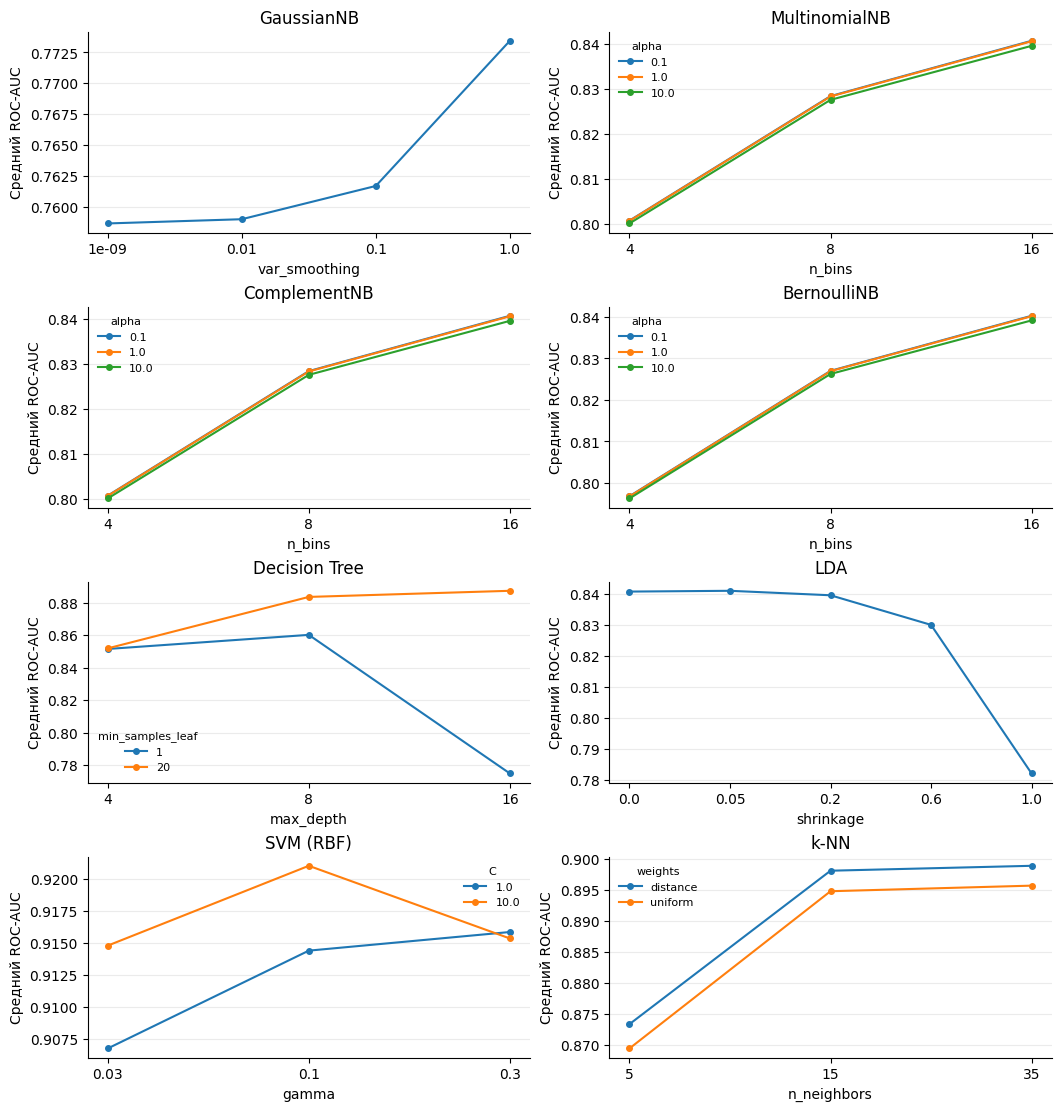

In [7]:
plot_params = {
    "GaussianNB": ("var_smoothing", None), "MultinomialNB": ("n_bins", "alpha"),
    "ComplementNB": ("n_bins", "alpha"), "BernoulliNB": ("n_bins", "alpha"),
    "Decision Tree": ("max_depth", "min_samples_leaf"), "LDA": ("shrinkage", None),
    "SVM (RBF)": ("gamma", "C"), "k-NN": ("n_neighbors", "weights"),
}
fig, axes = plt.subplots(4, 2, figsize=(10.5, 11), constrained_layout=True)
for (name, (x_param, series_param)), ax in zip(plot_params.items(), axes.flat):
    subset = cv_table.loc[cv_table["model"] == name].reset_index(drop=True)
    points = pd.DataFrame(subset["params"].map(json.loads).tolist())
    points["auc"] = subset["mean_auc"]
    groups = points.groupby(series_param) if series_param else [("", points)]
    for value, group in groups:
        group = group.sort_values(x_param)
        ax.plot(group[x_param].astype(str), group["auc"], marker="o",
                markersize=4, label=str(value))
    if series_param:
        ax.legend(title=series_param, fontsize=8, title_fontsize=8, frameon=False)
    ax.set(title=name, xlabel=x_param, ylabel="Средний ROC-AUC")
    ax.grid(axis="y", alpha=0.25)
show_figure(fig, "02_classical_tuning.png")

Результаты на трёх фолдах показывают, какие изменения параметров влияют сильнее всего.

- У **GaussianNB** увеличение `var_smoothing` с 10⁻⁹ до 1 подняло средний ROC-AUC с 0,7587 до 0,7734. Даже после сглаживания это наименьший результат среди проверенных методов.
- При `alpha=0,1` переход с 4 до 16 интервалов повысил ROC-AUC **MultinomialNB** и **ComplementNB** с 0,8007 до 0,8407, а **BernoulliNB** — с 0,7968 до 0,8403. При 16 интервалах изменение `alpha` от 0,1 до 10 дало разницу всего около 0,001. При двух классах дополнение одного класса совпадает со вторым. Для выбранных MultinomialNB и ComplementNB ранжирование совпало, а разные правила учёта априорных вероятностей влияют на решение при стандартном пороге.
- У **дерева** на глубине 16 увеличение минимального размера листа с 1 до 20 повысило ROC-AUC с 0,7748 до 0,8872. Объединение большего числа наблюдений в листе сделало оценку вероятности устойчивее.
- У **LDA** слабая регуляризация 0,05 дала 0,8410, близко к 0,8408 без регуляризации. При максимальном сжатии ковариационной матрицы результат упал до 0,7821.
- У **SVM** лучший средний ROC-AUC составил 0,9210 при `C=10` и `gamma=0,1`. Для того же `C` как уменьшение `gamma` до 0,03, так и увеличение до 0,3 ухудшило результат.
- У **k-NN** при взвешивании по расстоянию переход с 5 до 35 соседей повысил ROC-AUC с 0,8734 до 0,8989. Основная часть прироста пришлась на переход от 5 к 15 соседям.

Вертикальная шкала на рисунке своя для каждого метода. Все 54 конфигурации и их оценки доступны в таблице. [Результаты по фолдам](results/classical_cv.csv)

### 6. Нейронная сеть на TensorFlow

На вход подаются десять стандартизированных признаков. Базовая сеть содержит два полносвязных скрытых слоя из 64 и 32 нейронов с ReLU. Один выходной нейрон с сигмоидой оценивает вероятность гамма-сигнала. Для бинарной задачи используем бинарную кросс-энтропию и оптимизатор Adam с шагом 0,001.

Относительно базовой конфигурации (20 эпох, батч 128) меняем по одному параметру. Проверим 8 и 40 эпох, батчи 32 и 256, уменьшение ширины первого слоя, добавление третьего скрытого слоя и переход на tanh. У каждой конфигурации свой запуск TensorBoard. Выбираем сеть по **точному ROC-AUC валидации на последней заданной эпохе**. Одинаковый seed и один и тот же набор валидации позволяют сравнивать варианты между собой.

In [8]:
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "2")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
import tensorflow as tf
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
base_config = {"hidden": (64, 32), "activation": "relu", "epochs": 20, "batch": 128}
variants = {
    "base": {}, "epochs_8": {"epochs": 8}, "epochs_40": {"epochs": 40},
    "batch_32": {"batch": 32}, "batch_256": {"batch": 256},
    "width_32": {"hidden": (32, 32)}, "depth_3": {"hidden": (64, 32, 16)},
    "tanh": {"activation": "tanh"},
}
configs = {name: {**base_config, **change} for name, change in variants.items()}

def build_network(config):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    layers = [tf.keras.Input(shape=(len(FEATURES),))]
    for width in config["hidden"]:
        layers.append(tf.keras.layers.Dense(width, activation=config["activation"]))
    layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))
    network = tf.keras.Sequential(layers)
    network.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy", metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy")],
    )
    return network

def batches(features, labels, batch_size, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((features, np.asarray(labels, dtype="float32")))
    if shuffle:
        ds = ds.shuffle(len(labels), seed=SEED, reshuffle_each_iteration=True)
    opts = tf.data.Options()
    opts.threading.private_threadpool_size = 1
    return ds.batch(batch_size).with_options(opts).prefetch(1)

neural_scaler = StandardScaler().fit(X_train)
nn_train = neural_scaler.transform(X_train).astype("float32")
nn_val = neural_scaler.transform(X_val).astype("float32")
print(f"TensorFlow {tf.__version__}, Keras {tf.keras.__version__}")
build_network(base_config).summary()

TensorFlow 2.20.0, Keras 3.12.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,817 (11.00 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
board_root = Path("logs/tensorboard")
log_dir = board_root / "report"
if log_dir.exists():
    stamp = datetime.now(timezone.utc).strftime("%Y%m%d-%H%M%S-%f")
    log_dir = board_root / "repeats" / stamp
log_dir.mkdir(parents=True)

nn_runs = []
for name, config in configs.items():
    model = build_network(config)
    batch = config["batch"]
    logger = tf.keras.callbacks.TensorBoard(
        log_dir=str(log_dir / name), update_freq="epoch", write_graph=False,
        histogram_freq=0, profile_batch=0,
    )
    history = model.fit(
        batches(nn_train, y_train, batch, shuffle=True),
        validation_data=batches(nn_val, y_val, batch),
        epochs=config["epochs"], callbacks=[logger], verbose=0,
    )
    probability = model(nn_val, training=False).numpy().ravel()
    nn_runs.append({
        "run": name, "hidden": " × ".join(map(str, config["hidden"])),
        "activation": config["activation"], "batch": batch, "epochs": config["epochs"],
        "parameters": model.count_params(), "val_loss": history.history["val_loss"][-1],
        "val_accuracy": history.history["val_accuracy"][-1],
        "val_auc": roc_auc_score(y_val, probability),
    })

nn_table = pd.DataFrame(nn_runs).set_index("run")
nn_table["delta_auc"] = nn_table["val_auc"] - nn_table.loc["base", "val_auc"]
nn_table.to_csv(RESULTS / "neural_experiments.csv")
display(nn_table.round(4))
best_run = nn_table["val_auc"].idxmax()
validation_auc["MLP (Keras)"] = nn_table.loc[best_run, "val_auc"]
print(f"Выбран запуск {best_run}. Каталог TensorBoard: {log_dir}")

,hidden,activation,batch,epochs,parameters,val_loss,val_accuracy,val_auc,delta_auc
run,,,,,,,,,
base,64 × 32,relu,128,20,2817,0.3132,0.8715,0.9246,0.0000
epochs_8,64 × 32,relu,128,8,2817,0.3298,0.8659,0.9157,-0.0089
epochs_40,64 × 32,relu,128,40,2817,0.3077,0.8746,0.9266,0.0020
batch_32,64 × 32,relu,32,20,2817,0.3078,0.8738,0.9266,0.0020
batch_256,64 × 32,relu,256,20,2817,0.3206,0.8686,0.9218,-0.0028
width_32,32 × 32,relu,128,20,1441,0.3185,0.8662,0.9217,-0.0028
depth_3,64 × 32 × 16,relu,128,20,3329,0.3104,0.8741,0.9254,0.0009
tanh,64 × 32,tanh,128,20,2817,0.3243,0.8635,0.9198,-0.0048


Выбран запуск epochs_40. Каталог TensorBoard: logs/tensorboard/report


У базовой сети ROC-AUC на валидации вырос с 0,9157 за 8 эпох до 0,9246 за 20 и до 0,9266 за 40. При фиксированных 20 эпохах маленький батч 32 тоже дал 0,9266, а большой батч 256 — 0,9218. С маленьким батчем Adam выполняет больше обновлений за эпоху.

Уменьшение ширины первого слоя с 64 до 32 нейронов снизило оценку до 0,9217. Дополнительный слой из 16 нейронов поднял её до 0,9254. Замена ReLU на tanh дала 0,9198. По полному значению ROC-AUC выбран `epochs_40` (0,926608). У ближайшего варианта `batch_32` получилось 0,926551. Столь малая разница показывает чувствительность выбора двух лучших конфигураций к конкретной валидационной выборке.

#### 6.1. Кривые обучения и TensorBoard

Callback `TensorBoard` записывает `epoch_loss` и `epoch_accuracy` отдельно для обучения и валидации. Ниже эти значения читаются непосредственно из файлов событий. В интерфейсе TensorBoard во вкладке **Time Series** можно наложить кривые разных запусков и посмотреть значения в отдельные эпохи.

Из корня репозитория сохранённые кривые открываются командой `tensorboard --logdir logs/tensorboard/report`. Для просмотра внутри Jupyter подойдут две команды в отдельной ячейке.

~~~python
%load_ext tensorboard
%tensorboard --logdir logs/tensorboard/report
~~~

При повторном выполнении ноутбука новые журналы получат отдельный каталог в `logs/tensorboard/repeats/`. Для просмотра нового запуска используется путь, напечатанный предыдущей ячейкой.

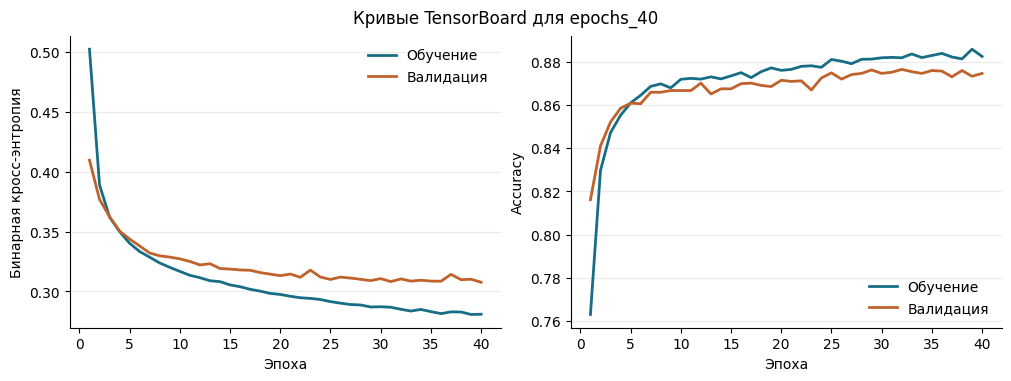

In [10]:
curves = []
for run, config in configs.items():
    for split in ["train", "validation"]:
        events = EventAccumulator(str(log_dir / run / split), size_guidance={"tensors": 0})
        events.Reload()
        series = {}
        for metric in ["loss", "accuracy"]:
            series[metric] = {
                item.step + 1: float(tf.make_ndarray(item.tensor_proto).item())
                for item in events.Tensors(f"epoch_{metric}")
            }
            assert set(series[metric]) == set(range(1, config["epochs"] + 1))
        for epoch in sorted(series["loss"]):
            curves.append({"run": run, "split": split, "epoch": epoch,
                           "loss": series["loss"][epoch], "accuracy": series["accuracy"][epoch]})

tb_history = pd.DataFrame(curves)
tb_history.to_csv(RESULTS / "tensorboard_history.csv", index=False)
chosen_curves = tb_history.loc[tb_history["run"] == best_run]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), constrained_layout=True)
for ax, metric, title in zip(axes, ["loss", "accuracy"], ["Бинарная кросс-энтропия", "Accuracy"]):
    for split, label, color in [("train", "Обучение", "#176d85"),
                                ("validation", "Валидация", "#bf622b")]:
        curve = chosen_curves.loc[chosen_curves["split"] == split]
        ax.plot(curve["epoch"], curve[metric], label=label, color=color, lw=2)
    ax.set(xlabel="Эпоха", ylabel=title)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(frameon=False)
fig.suptitle(f"Кривые TensorBoard для {best_run}")
show_figure(fig, "03_neural_learning.png")

За 40 эпох потери на обучении снизились с 0,5024 до 0,2810, на валидации — с 0,4097 до 0,3077. После 20-й эпохи улучшение замедлилось. К концу обучения Accuracy составила 0,8825 на обучающей выборке и 0,8746 на валидационной. В пределах эксперимента валидационные потери продолжали постепенно снижаться с небольшими колебаниями.

### 7. Сравнительный анализ

Сведём лучшие конфигурации в одну таблицу валидации и зафиксируем выбор модели до расчёта тестовых метрик. Затем переобучим восемь классических моделей и выбранную архитектуру сети на объединённых 80% данных. У сети сохраняются выбранные число эпох, размер батча и остальные параметры.

In [11]:
ranking = pd.Series(validation_auc, name="validation_auc").sort_values(ascending=False)
ranking.index.name = "model"
ranking.to_csv(RESULTS / "validation_auc.csv")
preferred, runner_up = ranking.index[:2]
display(ranking.round(4).to_frame())
print(f"Выбор по валидации: {preferred}. Ближайший результат: {runner_up}.")

,validation_auc
model,
MLP (Keras),0.9266
SVM (RBF),0.9241
k-NN,0.8967
Decision Tree,0.8745
MultinomialNB,0.8370
ComplementNB,0.8370
BernoulliNB,0.8365
LDA,0.8338
GaussianNB,0.7668


Выбор по валидации: MLP (Keras). Ближайший результат: SVM (RBF).


In [12]:
scores, predictions = {}, {}
for name, estimator in best_estimators.items():
    final_estimator = clone(estimator).fit(X_dev, y_dev)
    scores[name] = signal_score(final_estimator, X_test)
    predictions[name] = final_estimator.predict(X_test)

dev_scaler = StandardScaler().fit(X_dev)
nn_dev = dev_scaler.transform(X_dev).astype("float32")
nn_test = dev_scaler.transform(X_test).astype("float32")
final_config = configs[best_run]
final_net = build_network(final_config)
final_net.fit(batches(nn_dev, y_dev, final_config["batch"], shuffle=True),
              epochs=final_config["epochs"], verbose=0)
scores["MLP (Keras)"] = final_net(nn_test, training=False).numpy().ravel()
predictions["MLP (Keras)"] = (scores["MLP (Keras)"] >= 0.5).astype(int)

rows = []
export = pd.DataFrame({"source_row": X_test.index + 1, "y_true": y_test.to_numpy()})
for name, pred in predictions.items():
    rows.append({
        "model": name, "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, scores[name]),
    })
    export[f"score_{name}"] = scores[name].astype("float64")
    export[f"pred_{name}"] = pred
metrics = pd.DataFrame(rows).set_index("model").sort_values("ROC-AUC", ascending=False)
metrics.to_csv(RESULTS / "test_metrics.csv")
export.to_csv(RESULTS / "test_predictions.csv", index=False)
display(metrics.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
model,,,,,
MLP (Keras),0.8590,0.8716,0.9193,0.8948,0.9213
SVM (RBF),0.8672,0.8566,0.9566,0.9038,0.9185
k-NN,0.8310,0.8112,0.9655,0.8817,0.8974
Decision Tree,0.8408,0.8632,0.8982,0.8804,0.8842
MultinomialNB,0.7622,0.7594,0.9303,0.8362,0.8367
ComplementNB,0.7770,0.7976,0.8820,0.8377,0.8367
BernoulliNB,0.7636,0.7610,0.9294,0.8368,0.8363
LDA,0.7744,0.7823,0.9063,0.8398,0.8338
GaussianNB,0.7345,0.7136,0.9903,0.8295,0.7701


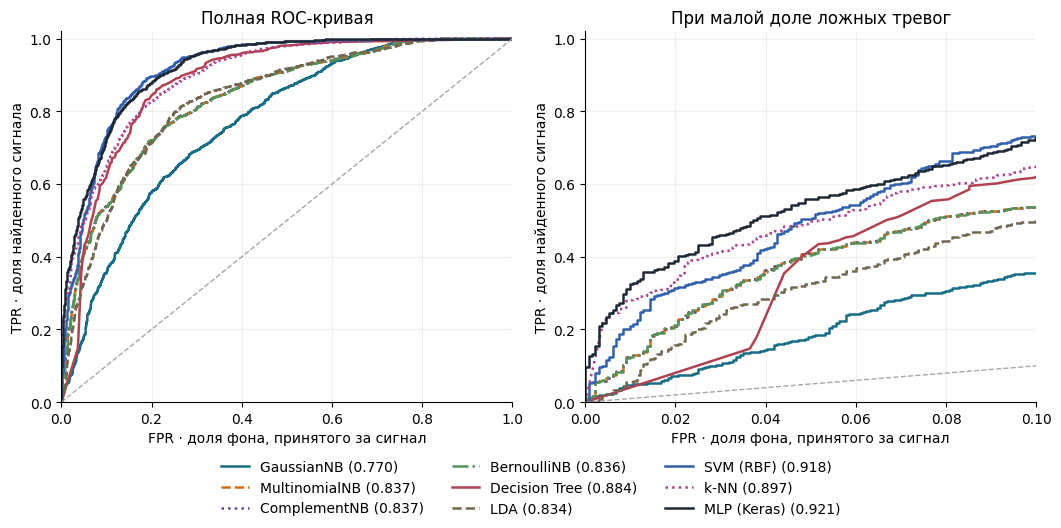

,"TPR при FPR ≤ 0,05"
MLP (Keras),0.5588
SVM (RBF),0.5045


In [13]:
colors = dict(zip(scores, ["#176d85", "#d66d14", "#674493", "#56935a", "#af4351",
                           "#726850", "#3260ad", "#a9428d", "#1e2935"]))
line_styles = ["-", "--", ":", "-.", "-", "--", "-", ":", "-"]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 5.2), constrained_layout=True)
roc_handles = []
low_fpr_recall = {}
for (name, score), style in zip(scores.items(), line_styles):
    fpr, tpr, _ = roc_curve(y_test, score)
    low_fpr_recall[name] = tpr[fpr <= 0.05].max()
    for ax in axes:
        line, = ax.plot(fpr, tpr, color=colors[name], linestyle=style, lw=1.8,
                        label=f"{name} ({metrics.loc[name, 'ROC-AUC']:.3f})")
    roc_handles.append(line)
for ax, x_max, title in zip(axes, [1, 0.10], ["Полная ROC-кривая", "При малой доле ложных тревог"]):
    ax.plot([0, x_max], [0, x_max], color="0.65", lw=1, ls="--")
    ax.set(xlim=(0, x_max), ylim=(0, 1.02), xlabel="FPR · доля фона, принятого за сигнал",
           ylabel="TPR · доля найденного сигнала", title=title)
    ax.grid(alpha=0.2)
fig.legend(handles=roc_handles, loc="outside lower center", ncols=3, frameon=False)
show_figure(fig, "04_roc.png")
display(pd.Series(low_fpr_recall, name="TPR при FPR ≤ 0,05")
        .loc[[preferred, runner_up]].round(4).to_frame())

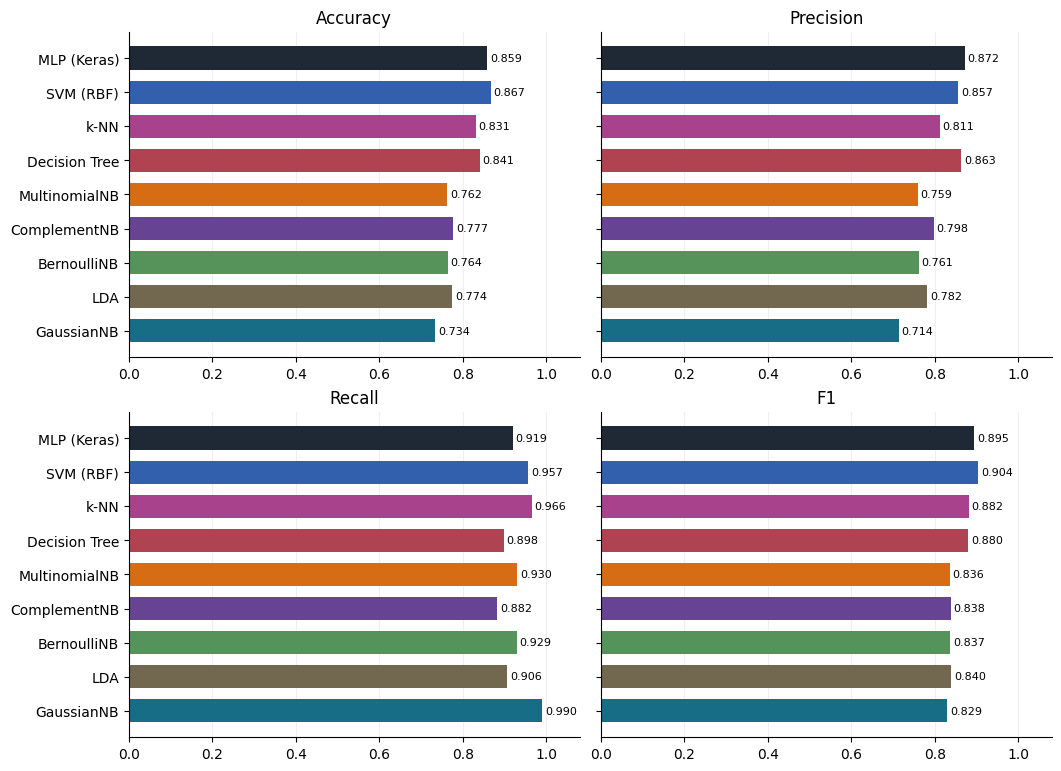

In [14]:
order = metrics.index[::-1]
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.6), sharey=True, constrained_layout=True)
for ax, metric in zip(axes.flat, ["Accuracy", "Precision", "Recall", "F1"]):
    values = metrics.loc[order, metric]
    bars = ax.barh(order, values, color=[colors[name] for name in order], height=0.68)
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
    ax.set(title=metric, xlim=(0, 1.08), xticks=np.arange(0, 1.01, 0.2))
    ax.grid(axis="x", alpha=0.2)
show_figure(fig, "05_metrics.png")

На тесте **MLP** лучше ранжирует события по ROC-AUC (0,9213) и даёт самую высокую Precision (0,8716). На участке кривой с FPR ≤ 5% максимальный Recall у MLP равен 55,9%, у SVM — 50,4%. Это сравнение точек эмпирической ROC-кривой.

При стандартных порогах **SVM** показывает лучшие Accuracy (0,8672) и F1 (0,9038). Она пропустила 107 гамма-событий против 199 у сети, но приняла за сигнал 395 фоновых событий против 334. Самая высокая Recall у GaussianNB (0,9903) сочетается с Precision 0,7136. По одной чувствительности такой классификатор можно переоценить.

#### 7.1. Ошибки лучшей модели и устойчивость сравнения

Для модели, выбранной по валидации, посмотрим матрицу ошибок. Для двух лидеров валидации оценим разность тестовых ROC-AUC парным стратифицированным бутстрэпом. В каждой из 1 000 повторных выборок берём одни и те же события для обеих моделей, сохраняя исходное число сигналов и фона. Интервал по процентилям 2,5 и 97,5% отражает вариацию тестовых событий при фиксированных обученных моделях.

In [15]:
cm = confusion_matrix(y_test, predictions[preferred], labels=[0, 1])
display(pd.DataFrame(cm, index=["На самом деле фон", "На самом деле гамма"],
                     columns=["Решение: фон", "Решение: гамма"]))
y_array = y_test.to_numpy()
gamma_index = np.flatnonzero(y_array == 1)
background_index = np.flatnonzero(y_array == 0)
rng = np.random.default_rng(SEED)
differences = []
for _ in range(1000):
    sample = np.concatenate([rng.choice(gamma_index, len(gamma_index), replace=True),
                             rng.choice(background_index, len(background_index), replace=True)])
    first = roc_auc_score(y_array[sample], scores[preferred][sample])
    second = roc_auc_score(y_array[sample], scores[runner_up][sample])
    differences.append(first - second)
observed = metrics.loc[preferred, "ROC-AUC"] - metrics.loc[runner_up, "ROC-AUC"]
interval = np.quantile(differences, [0.025, 0.975])
print(f"{preferred} минус {runner_up}: ΔROC-AUC = {observed:.4f}, "
      f"95% интервал [{interval[0]:.4f}, {interval[1]:.4f}]")

,Решение: фон,Решение: гамма
На самом деле фон,981,334
На самом деле гамма,199,2267


MLP (Keras) минус SVM (RBF): ΔROC-AUC = 0.0028, 95% интервал [-0.0025, 0.0081]


### 8. Заключение

После очистки в эксперимент вошли 18 905 событий. На едином тесте из 3 781 события сравнивались девять классификаторов. Из классических моделей наибольший ROC-AUC показала SVM с RBF-ядром (0,9185). Её F1 при стандартном пороге составил 0,9038.

По выбранному заранее критерию **для ранжирования гамма-кандидатов я выбираю MLP с двумя слоями на 64 и 32 нейрона, ReLU, батчем 128 и 40 эпохами**. Она заняла первое место по ROC-AUC на валидации (0,9266) и на тесте (0,9213). На тесте при пороге 0,5 сеть распознала 2 267 из 2 466 гамма-событий и ошибочно отнесла к сигналу 334 из 1 315 фоновых. Разница ROC-AUC с SVM составила 0,0028, а парный 95%-й бутстрэп-интервал — от −0,0025 до 0,0081. Интервал включает ноль, поэтому при повторной выборке близкие по качеству модели могут поменяться местами.

Результаты относятся к моделированию MAGIC. В настоящих наблюдениях, по описанию UCI, преобладает фон. При переносе модели на данные телескопа особенно важно заново оценить долю ложных тревог и чистоту отобранного сигнала.

### 9. Источники

1. Bock R. K. и др. *Methods for multidimensional event classification: a case study using images from a Cherenkov gamma-ray telescope*. Nuclear Instruments and Methods in Physics Research A, 516 (2004), 511–528. [Публикация](https://ui.adsabs.harvard.edu/abs/2004NIMPA.516..511B/abstract)
2. MAGIC Gamma Telescope, описание признаков, метода моделирования и состава классов. [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/159/magic+gamma+telescope)
3. MAGIC Gamma Telescope Dataset. [Карточка на Kaggle](https://www.kaggle.com/datasets/abhinand05/magic-gamma-telescope-dataset)
4. Алгоритмы классификации, преобразования признаков и метрики. [Руководство Scikit-Learn](https://scikit-learn.org/stable/user_guide.html)
5. Построение и обучение полносвязной сети. [TensorFlow и Keras](https://www.tensorflow.org/guide/keras)
6. Запись событий и просмотр кривых обучения. [Руководство TensorBoard](https://www.tensorflow.org/tensorboard/get_started)